In [ ]:
!pip install tensorflow shap reportlab imbalanced-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 75.0 MB/s eta 0:00:00


In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_recall_curve
)

from imblearn.over_sampling import SMOTE

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam

import shap

print("Libraries Imported Successfully")

Libraries Imported Successfully


In [ ]:
stroke_df = pd.read_csv("/content/healthcare-dataset-stroke-data (1).csv")

stroke_df.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [ ]:
print("Shape :", stroke_df.shape)

print("\nColumns")

print(stroke_df.columns)

print("\nMissing Values")

print(stroke_df.isnull().sum())

print("\nStroke Distribution")

print(stroke_df["stroke"].value_counts())

Shape : (5110, 12)

Columns
Index(['id', 'gender', 'age', 'hypertension', 'heart_disease', 'ever_married',
       'work_type', 'Residence_type', 'avg_glucose_level', 'bmi',
       'smoking_status', 'stroke'],
      dtype='object')

Missing Values
id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64

Stroke Distribution
stroke
0    4861
1     249
Name: count, dtype: int64


In [ ]:
stroke_df.drop("id", axis=1, inplace=True)

print("ID Removed Successfully")

stroke_df.head()

ID Removed Successfully


,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [ ]:
imputer = SimpleImputer(strategy="mean")

stroke_df["bmi"] = imputer.fit_transform(
    stroke_df[["bmi"]]
)

print(stroke_df.isnull().sum())

gender               0
age                  0
hypertension         0
heart_disease        0
ever_married         0
work_type            0
Residence_type       0
avg_glucose_level    0
bmi                  0
smoking_status       0
stroke               0
dtype: int64


In [ ]:
encoder = LabelEncoder()

categorical_columns = [

    "gender",

    "ever_married",

    "work_type",

    "Residence_type",

    "smoking_status"

]

for col in categorical_columns:

    stroke_df[col] = encoder.fit_transform(
        stroke_df[col]
    )

stroke_df.head()

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,1,67.0,0,1,1,2,1,228.69,36.600000,1,1
1,0,61.0,0,0,1,3,0,202.21,28.893237,2,1
2,1,80.0,0,1,1,2,0,105.92,32.500000,2,1
3,0,49.0,0,0,1,2,1,171.23,34.400000,3,1
4,0,79.0,1,0,1,3,0,174.12,24.000000,2,1


In [ ]:
X = stroke_df.drop("stroke", axis=1)

y = stroke_df["stroke"]

print(X.shape)

print(y.shape)

(5110, 10)
(5110,)


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(

    X,

    y,

    test_size=0.20,

    random_state=42,

    stratify=y

)

print("Training Shape :", X_train.shape)

print("Testing Shape :", X_test.shape)

Training Shape : (4088, 10)
Testing Shape : (1022, 10)


In [ ]:
smote = SMOTE(random_state=42)

X_train, y_train = smote.fit_resample(
    X_train,
    y_train
)

print("After SMOTE")

print(pd.Series(y_train).value_counts())

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

X_test = scaler.transform(X_test)

print("Scaling Completed Successfully")

After SMOTE
stroke
0    3889
1    3889
Name: count, dtype: int64
Scaling Completed Successfully


In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization

model = Sequential([

    Dense(128, activation='relu', input_shape=(X_train.shape[1],)),
    BatchNormalization(),
    Dropout(0.30),

    Dense(64, activation='relu'),
    BatchNormalization(),
    Dropout(0.30),

    Dense(32, activation='relu'),
    Dropout(0.20),

    Dense(16, activation='relu'),

    Dense(1, activation='sigmoid')

])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         1,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,057 (51.00 KB)

 Trainable params: 12,673 (49.50 KB)

 Non-trainable params: 384 (1.50 KB)

In [ ]:
from tensorflow.keras.optimizers import Adam

model.compile(

    optimizer=Adam(learning_rate=0.001),

    loss="binary_crossentropy",

    metrics=["accuracy"]

)

print("Model Compiled Successfully")

Model Compiled Successfully


In [ ]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(

    monitor="val_loss",

    patience=10,

    restore_best_weights=True

)

history = model.fit(

    X_train,

    y_train,

    validation_split=0.20,

    epochs=100,

    batch_size=32,

    callbacks=[early_stop],

    verbose=1

)

Epoch 1/100
195/195 ━━━━━━━━━━━━━━━━━━━━ 23s 55ms/step - accuracy: 0.7122 - loss: 0.5455 - val_accuracy: 0.6234 - val_loss: 0.6657
Epoch 2/100
195/195 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.7970 - loss: 0.4183 - val_accuracy: 0.7956 - val_loss: 0.5100
Epoch 3/100
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8071 - loss: 0.4052 - val_accuracy: 0.8683 - val_loss: 0.4035
Epoch 4/100
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8218 - loss: 0.3874 - val_accuracy: 0.8927 - val_loss: 0.3440
Epoch 5/100
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8179 - loss: 0.3864 - val_accuracy: 0.8753 - val_loss: 0.3973
Epoch 6/100
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8211 - loss: 0.3775 - val_accuracy: 0.8573 - val_loss: 0.4364
Epoch 7/100
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8222 - loss: 0.3768 - val_accuracy: 0.8387 - val_loss: 0.4243
Epoch 8/100
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8274 - loss: 0.3662 - val_ac

In [ ]:
loss, accuracy = model.evaluate(X_test, y_test, verbose=0)

print("Test Accuracy :", round(accuracy*100,2), "%")

y_pred_prob = model.predict(X_test)

y_pred = (y_pred_prob >= 0.5).astype(int)

from sklearn.metrics import classification_report, confusion_matrix

print("\nClassification Report\n")

print(classification_report(y_test, y_pred))

print("\nConfusion Matrix\n")

print(confusion_matrix(y_test, y_pred))

In [ ]:
from sklearn.metrics import precision_recall_curve
import numpy as np

precision, recall, thresholds = precision_recall_curve(

    y_test,

    y_pred_prob

)

f1 = (2*precision*recall)/(precision+recall+1e-10)

best_index = np.argmax(f1)

BEST_THRESHOLD = thresholds[best_index]

print("Best Threshold :", round(BEST_THRESHOLD,3))

Best Threshold : 0.536


In [ ]:
y_pred_best = (y_pred_prob >= BEST_THRESHOLD).astype(int)

print(classification_report(y_test, y_pred_best))

print(confusion_matrix(y_test, y_pred_best))

              precision    recall  f1-score   support

           0       0.97      0.85      0.91       972
           1       0.16      0.54      0.24        50

    accuracy                           0.83      1022
   macro avg       0.56      0.69      0.57      1022
weighted avg       0.93      0.83      0.87      1022

[[825 147]
 [ 23  27]]


In [ ]:
import shap

background = X_train[:100]

explainer = shap.Explainer(model, background)

print("SHAP Explainer Created Successfully")

SHAP Explainer Created Successfully


In [ ]:
shap_values = explainer(X_test[:1])

print("SHAP Values Generated")

SHAP Values Generated


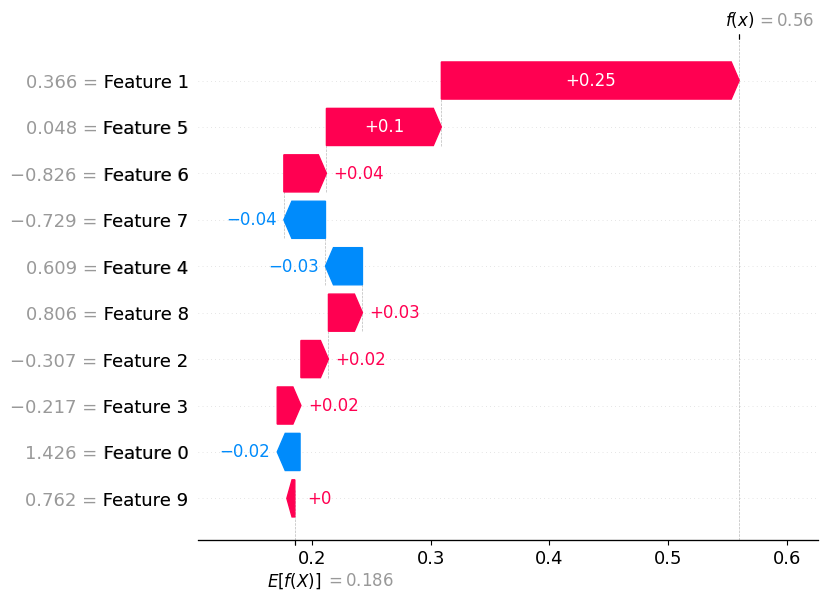

In [ ]:
shap.plots.waterfall(shap_values[0])

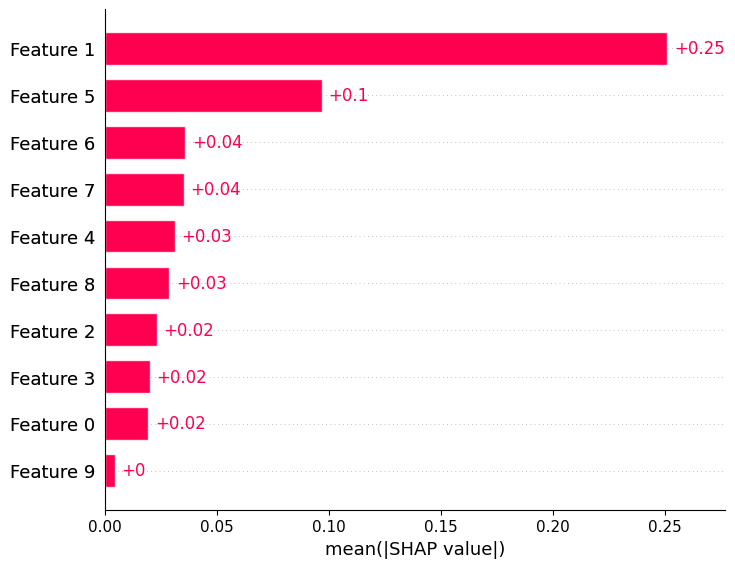

In [ ]:
shap.plots.bar(shap_values)

In [ ]:
class CoordinatorAgent:

    def __init__(self):
        print("Coordinator Agent Initialized")

    def start_workflow(self):
        print("="*60)
        print("Agentic AI Stroke Prediction Workflow Started")
        print("="*60)

In [ ]:
class ValidationAgent:

    def validate(self, patient):

        if patient.isnull().sum() > 0:
            return False, "Missing Values Found"

        if patient["age"] < 0 or patient["age"] > 120:
            return False, "Invalid Age"

        if patient["bmi"] <= 0:
            return False, "Invalid BMI"

        if patient["avg_glucose_level"] <= 0:
            return False, "Invalid Glucose Value"

        return True, "Validation Successful"

In [ ]:
class DataQualityAgent:

    def assess(self, patient):

        total_features = len(patient)

        missing = patient.isnull().sum()

        completeness = ((total_features - missing) / total_features) * 100

        quality = "Excellent"

        if completeness < 100:
            quality = "Good"

        if completeness < 90:
            quality = "Average"

        report = {

            "Completeness (%)": round(completeness,2),

            "Missing Features": int(missing),

            "Quality": quality

        }

        return report

In [ ]:

# ============================================================
# PATIENT PROFILE AGENT
# ============================================================

class PatientProfileAgent:

    def create_profile(self, patient):

        profile = {}

        # ====================================================
        # AGE
        # ====================================================

        profile["Age"] = patient["age"]

        # ====================================================
        # GENDER
        # ====================================================

        if patient["gender"] == 0:
            profile["Gender"] = "Female"
        else:
            profile["Gender"] = "Male"

        # ====================================================
        # BMI
        # ====================================================

        if patient["bmi"] < 18.5:
            profile["BMI"] = "Underweight"

        elif patient["bmi"] < 25:
            profile["BMI"] = "Normal"

        elif patient["bmi"] < 30:
            profile["BMI"] = "Overweight"

        else:
            profile["BMI"] = "Obese"

        # ====================================================
        # HYPERTENSION
        # ====================================================

        profile["Hypertension"] = (
            "Yes"
            if patient["hypertension"] == 1
            else "No"
        )

        # ====================================================
        # HEART DISEASE
        # ====================================================

        profile["Heart Disease"] = (
            "Yes"
            if patient["heart_disease"] == 1
            else "No"
        )

        # ====================================================
        # WORK TYPE
        # ====================================================

        work_type_mapping = {
            0: "Government Job",
            1: "Private Job",
            2: "Self-employed",
            3: "Children",
            4: "Never Worked"
        }

        profile["Work Type"] = work_type_mapping.get(
            int(patient["work_type"]),
            "Unknown"
        )

        # ====================================================
        # RESIDENCE TYPE
        # ====================================================

        residence_type_mapping = {
            0: "Rural",
            1: "Urban"
        }

        profile["Residence Type"] = residence_type_mapping.get(
            int(patient["Residence_type"]),
            "Unknown"
        )

        return profile

In [ ]:
class PredictionAgent:

    def __init__(self, model, threshold):
        self.model = model
        self.threshold = threshold

    def predict(self, patient):

        patient_df = pd.DataFrame([patient])

        patient_scaled = scaler.transform(patient_df)

        probability = float(self.model.predict(patient_scaled, verbose=0)[0][0])

        prediction = (
            "High Stroke Risk"
            if probability >= self.threshold
            else "Low Stroke Risk"
        )

        return probability, prediction

In [ ]:
class ExplainabilityAgent:

    def __init__(self, explainer, feature_names):
        self.explainer = explainer
        self.feature_names = feature_names

    def explain(self, patient):

        patient_df = pd.DataFrame([patient])

        patient_scaled = scaler.transform(patient_df)

        shap_values = self.explainer(patient_scaled)

        values = shap_values.values[0]

        importance = np.abs(values)

        top_index = np.argsort(importance)[::-1][:5]

        top_features = []

        for idx in top_index:
            top_features.append({
                "Feature": self.feature_names[idx],
                "Contribution": round(float(values[idx]), 4)
            })

        return top_features

In [ ]:
class ClinicalReasoningAgent:

    def generate_reasoning(self, prediction, probability, top_features):

        feature_names = [f["Feature"] for f in top_features]

        reasoning = f"""
Prediction Summary

Prediction : {prediction}

Probability : {probability:.3f}

Top Contributing Factors:
"""

        for feature in feature_names:
            reasoning += f"\n• {feature}"

        if prediction == "High Stroke Risk":

            reasoning += """

Clinical Interpretation:

The model predicts a HIGH stroke risk because the above clinical factors
collectively contributed most to the prediction. This patient should
undergo immediate medical evaluation and risk management.
"""

        else:

            reasoning += """

Clinical Interpretation:

The current stroke risk is LOW based on the available clinical features.
Routine monitoring and maintenance of a healthy lifestyle are recommended.
"""

        return reasoning

In [ ]:
# ============================================================
# UPDATED RISK STRATIFICATION AGENT
# ============================================================

class RiskStratificationAgent:

    def stratify(self, probability):

        if probability < BEST_THRESHOLD:
            return "Low Risk"

        elif probability < 0.80:
            return "High Risk"

        else:
            return "Critical Risk"


print("Updated Risk Stratification Agent created successfully!")
print("Model Prediction Threshold:", round(float(BEST_THRESHOLD), 3))


Updated Risk Stratification Agent created successfully!
Model Prediction Threshold: 0.536


In [ ]:
class DecisionSupportAgent:

    def decide(self, risk_level):

        decision = {

            "Low Risk":
                "Routine Health Monitoring",

            "Moderate Risk":
                "Lifestyle Modification and Periodic Screening",

            "High Risk":
                "Consult a Neurologist and Perform Further Clinical Tests",

            "Critical Risk":
                "Immediate Hospital Evaluation Recommended"

        }

        return decision[risk_level]

In [ ]:

class RecommendationAgent:

    def recommend(self, patient, risk_level):

        recommendations = []

        # ====================================================
        # GENERAL RECOMMENDATIONS
        # ====================================================

        if risk_level == "Low Risk":

            recommendations.append(
                "Maintain a healthy lifestyle."
            )

            recommendations.append(
                "Schedule regular annual health checkups."
            )

        elif risk_level == "Moderate Risk":

            recommendations.append(
                "Increase physical activity."
            )

            recommendations.append(
                "Monitor blood pressure and blood glucose regularly."
            )

        elif risk_level == "High Risk":

            recommendations.append(
                "Consult a neurologist."
            )

            recommendations.append(
                "Monitor cardiovascular health closely."
            )

            recommendations.append(
                "Follow a physician-prescribed treatment plan."
            )

        else:

            recommendations.append(
                "Seek immediate medical attention."
            )

            recommendations.append(
                "Do not ignore stroke warning symptoms."
            )


        # ====================================================
        # PERSONALIZED RECOMMENDATIONS
        # ====================================================

        if patient["bmi"] >= 30:

            recommendations.append(
                "Adopt a weight management plan."
            )


        if patient["heart_disease"] == 1:

            recommendations.append(
                "Regular cardiology follow-up is advised."
            )


        if patient["hypertension"] == 1:

            recommendations.append(
                "Maintain strict blood pressure control."
            )


        if patient["avg_glucose_level"] > 140:

            recommendations.append(
                "Monitor blood glucose regularly."
            )


        # ====================================================
        # FOOD-BASED RECOMMENDATIONS
        # ====================================================

        food_recommendations = []

        foods_to_limit = []

        food_reasons = []


        # ----------------------------------------------------
        # BASIC HEALTHY FOOD
        # ----------------------------------------------------

        food_recommendations.extend([

            "Fresh vegetables and leafy greens",

            "Fresh fruits in moderate portions",

            "Whole grains such as oats and brown rice",

            "Legumes and pulses",

            "Unsalted nuts and seeds"

        ])


        foods_to_limit.extend([

            "Deep-fried foods",

            "Highly processed foods",

            "Sugary drinks",

            "Excess sweets",

            "Excess salt"

        ])


        # ----------------------------------------------------
        # BMI BASED
        # ----------------------------------------------------

        if patient["bmi"] >= 25:

            food_recommendations.extend([

                "High-fiber foods",

                "Vegetable-based meals",

                "Low-fat protein sources"

            ])

            foods_to_limit.extend([

                "High-calorie foods",

                "Fast food",

                "Large portions"

            ])

            food_reasons.append(
                "BMI is above the normal range, "
                "so a balanced and calorie-conscious "
                "diet is recommended."
            )


        # ----------------------------------------------------
        # HYPERTENSION BASED
        # ----------------------------------------------------

        if patient["hypertension"] == 1:

            food_recommendations.extend([

                "Low-sodium foods",

                "Fresh vegetables",

                "Unsalted nuts"

            ])

            foods_to_limit.extend([

                "Salty snacks",

                "Pickles",

                "Processed meats",

                "High-sodium packaged foods"

            ])

            food_reasons.append(
                "Hypertension is present, so "
                "lower-sodium food choices are recommended."
            )


        # ----------------------------------------------------
        # GLUCOSE BASED
        # ----------------------------------------------------

        if patient["avg_glucose_level"] > 140:

            food_recommendations.extend([

                "High-fiber vegetables",

                "Whole grains",

                "Legumes"

            ])

            foods_to_limit.extend([

                "Sugary drinks",

                "Sweets",

                "Refined carbohydrates"

            ])

            food_reasons.append(
                "Average glucose is elevated, so "
                "limiting added sugar and refined "
                "carbohydrates is recommended."
            )


        # ----------------------------------------------------
        # HEART DISEASE BASED
        # ----------------------------------------------------

        if patient["heart_disease"] == 1:

            food_recommendations.extend([

                "Vegetables",

                "Whole grains",

                "Fish or other lean protein sources"

            ])

            foods_to_limit.extend([

                "Foods high in saturated fat",

                "Deep-fried foods",

                "Processed meats"

            ])

            food_reasons.append(
                "Heart disease is present, so "
                "heart-friendly food choices are recommended."
            )


        # ====================================================
        # REMOVE DUPLICATES
        # ====================================================

        food_recommendations = list(
            dict.fromkeys(
                food_recommendations
            )
        )

        foods_to_limit = list(
            dict.fromkeys(
                foods_to_limit
            )
        )


        # ====================================================
        # RETURN ALL RESULTS
        # ====================================================

        return {

            "recommendations":
                recommendations,

            "food_recommendations":
                food_recommendations,

            "foods_to_limit":
                foods_to_limit,

            "food_reasons":
                food_reasons
        }

In [ ]:
!pip install reportlab

In [ ]:

# ============================================================
# PDF REPORT AGENT
# ============================================================

from reportlab.lib.styles import getSampleStyleSheet
from reportlab.platypus import SimpleDocTemplate, Paragraph
from datetime import datetime


class PDFReportAgent:

    def generate_report(

        self,

        profile,

        probability,

        prediction,

        top_features,

        reasoning,

        risk_level,

        decision,

        recommendations,

        food_recommendations,

        foods_to_limit,

        food_reasons

    ):

        filename = "Stroke_Risk_Report.pdf"

        doc = SimpleDocTemplate(
            filename
        )

        styles = getSampleStyleSheet()

        story = []


        # ====================================================
        # TITLE
        # ====================================================

        story.append(

            Paragraph(
                "<b>Stroke Risk Prediction Report</b>",
                styles["Title"]
            )

        )

        story.append(

            Paragraph(
                f"Generated On : {datetime.now()}",
                styles["Normal"]
            )

        )


        # ====================================================
        # PATIENT PROFILE
        # ====================================================

        story.append(

            Paragraph(
                "<br/><b>Patient Profile</b>",
                styles["Heading2"]
            )

        )

        for key in [
            "Age",
            "Gender",
            "BMI",
            "Hypertension",
            "Heart Disease"
        ]:

            if key in profile:

                story.append(

                    Paragraph(
                        f"{key}: {profile[key]}",
                        styles["Normal"]
                    )

                )


        # ====================================================
        # PREDICTION
        # ====================================================

        story.append(

            Paragraph(
                "<br/><b>Prediction</b>",
                styles["Heading2"]
            )

        )

        story.append(

            Paragraph(
                prediction,
                styles["Normal"]
            )

        )

        story.append(

            Paragraph(
                f"Probability : {probability:.3f}",
                styles["Normal"]
            )

        )


        # ====================================================
        # RISK LEVEL
        # ====================================================

        story.append(

            Paragraph(
                "<br/><b>Risk Level</b>",
                styles["Heading2"]
            )

        )

        story.append(

            Paragraph(
                risk_level,
                styles["Normal"]
            )

        )


        # ====================================================
        # IMPORTANT PATIENT FACTORS
        # ====================================================

        story.append(

            Paragraph(
                "<br/><b>Important Patient Factors</b>",
                styles["Heading2"]
            )

        )

        for key in [

            "Gender",
            "BMI",
            "Hypertension",
            "Heart Disease",
            "Work Type",
            "Residence Type"

        ]:

            if key in profile:

                story.append(

                    Paragraph(
                        f"{key}: {profile[key]}",
                        styles["Normal"]
                    )

                )


        # ====================================================
        # CLINICAL REASONING
        # ====================================================

        story.append(

            Paragraph(
                "<br/><b>Clinical Reasoning</b>",
                styles["Heading2"]
            )

        )

        story.append(

            Paragraph(
                reasoning.replace(
                    "\n",
                    "<br/>"
                ),
                styles["Normal"]
            )

        )


        # ====================================================
        # DECISION SUPPORT
        # ====================================================

        story.append(

            Paragraph(
                "<br/><b>Decision Support</b>",
                styles["Heading2"]
            )

        )

        story.append(

            Paragraph(
                decision,
                styles["Normal"]
            )

        )


        # ====================================================
        # GENERAL RECOMMENDATIONS
        # ====================================================

        story.append(

            Paragraph(
                "<br/><b>Recommendations</b>",
                styles["Heading2"]
            )

        )

        for rec in recommendations:

            story.append(

                Paragraph(
                    f"• {rec}",
                    styles["Normal"]
                )

            )


        # ====================================================
        # PERSONALIZED FOOD RECOMMENDATIONS
        # ====================================================

        story.append(

            Paragraph(
                "<br/><b>"
                "Personalized Food Recommendations"
                "</b>",
                styles["Heading2"]
            )

        )


        # ====================================================
        # FOOD RECOMMENDATION REASONS
        # ====================================================

        if food_reasons:

            story.append(

                Paragraph(
                    "<b>Why these recommendations?</b>",
                    styles["Heading3"]
                )

            )

            for reason in food_reasons:

                story.append(

                    Paragraph(
                        f"• {reason}",
                        styles["Normal"]
                    )

                )


        # ====================================================
        # FOODS TO PREFER
        # ====================================================

        story.append(

            Paragraph(
                "<br/><b>Foods to Prefer</b>",
                styles["Heading3"]
            )

        )

        for food in food_recommendations:

            story.append(

                Paragraph(
                    f"✓ {food}",
                    styles["Normal"]
                )

            )


        # ====================================================
        # FOODS TO LIMIT
        # ====================================================

        story.append(

            Paragraph(
                "<br/><b>Foods to Limit</b>",
                styles["Heading3"]
            )

        )

        for food in foods_to_limit:

            story.append(

                Paragraph(
                    f"✗ {food}",
                    styles["Normal"]
                )

            )


        # ====================================================
        # DISCLAIMER
        # ====================================================

        story.append(

            Paragraph(
                "<br/><b>Important Note</b>",
                styles["Heading2"]
            )

        )

        story.append(

            Paragraph(
                "Food recommendations are general "
                "dietary guidance based on the available "
                "patient information and should not replace "
                "professional medical or dietary advice.",
                styles["Normal"]
            )

        )


        # ====================================================
        # BUILD PDF
        # ====================================================

        doc.build(
            story
        )

        return filename

In [ ]:
# ============================================================
# FINAL STROKE PREDICTION WORKFLOW
# ============================================================


# ============================================================
# SELECT A PATIENT
# ============================================================

patient_index = int(
    input(
        "Enter Patient Index (0 to 5109): "
    )
)


patient = (
    stroke_df
    .iloc[patient_index]
    .drop("stroke")
)


# ============================================================
# INITIALIZE AGENTS
# ============================================================

coordinator = CoordinatorAgent()

validator = ValidationAgent()

quality_agent = DataQualityAgent()

profile_agent = PatientProfileAgent()

prediction_agent = PredictionAgent(
    model,
    BEST_THRESHOLD
)

explain_agent = ExplainabilityAgent(
    explainer,
    X.columns.tolist()
)

reasoning_agent = ClinicalReasoningAgent()

risk_agent = RiskStratificationAgent()

decision_agent = DecisionSupportAgent()

recommendation_agent = RecommendationAgent()

pdf_agent = PDFReportAgent()


# ============================================================
# START WORKFLOW
# ============================================================

coordinator.start_workflow()


# ============================================================
# VALIDATION
# ============================================================

status, message = validator.validate(
    patient
)

print(message)


if not status:

    raise ValueError(
        "Invalid Patient Data"
    )


# ============================================================
# DATA QUALITY
# ============================================================

quality = quality_agent.assess(
    patient
)

print("\nData Quality")

print(quality)


# ============================================================
# PATIENT PROFILE
# ============================================================

profile = profile_agent.create_profile(
    patient
)

print("\nPatient Profile")

print(profile)


# ============================================================
# PREDICTION
# ============================================================

probability, prediction = (
    prediction_agent.predict(
        patient
    )
)

print("\nPrediction")

print(prediction)

print(
    f"Stroke Probability : "
    f"{probability:.3f}"
)


# ============================================================
# SHAP EXPLAINABILITY
# ============================================================

top_features = (
    explain_agent.explain(
        patient
    )
)

print("\nTop Features")

for feature in top_features:

    print(feature)


# ============================================================
# CLINICAL REASONING
# ============================================================

reasoning = (
    reasoning_agent.generate_reasoning(

        prediction,

        probability,

        top_features

    )
)

print("\nClinical Reasoning")

print(reasoning)


# ============================================================
# RISK STRATIFICATION
# ============================================================

risk_level = (
    risk_agent.stratify(
        probability
    )
)

print("\nRisk Level")

print(risk_level)


# ============================================================
# DECISION SUPPORT
# ============================================================

decision = (
    decision_agent.decide(
        risk_level
    )
)

print("\nDecision")

print(decision)


# ============================================================
# PERSONALIZED RECOMMENDATION AGENT
# ============================================================

recommendation_result = (

    recommendation_agent.recommend(

        patient,

        risk_level

    )

)




# ============================================================
# EXTRACT GENERAL RECOMMENDATIONS
# ============================================================

recommendations = (

    recommendation_result[
        "recommendations"
    ]

)


# ============================================================
# EXTRACT FOOD RECOMMENDATIONS
# ============================================================

food_recommendations = (

    recommendation_result[
        "food_recommendations"
    ]

)


foods_to_limit = (

    recommendation_result[
        "foods_to_limit"
    ]

)


food_reasons = (

    recommendation_result[
        "food_reasons"
    ]

)


# ============================================================
# DISPLAY GENERAL RECOMMENDATIONS
# ============================================================

print(
    "\nRecommendations"
)

for rec in recommendations:

    print(
        "•",
        rec
    )


# ============================================================
# DISPLAY FOOD RECOMMENDATIONS
# ============================================================

print(
    "\n" + "=" * 60
)

print(
    "PERSONALIZED FOOD RECOMMENDATIONS"
)

print(
    "=" * 60
)


print(
    "\nFoods to Prefer:"
)

for food in food_recommendations:

    print(
        "✓",
        food
    )


print(
    "\nFoods to Limit:"
)

for food in foods_to_limit:

    print(
        "✗",
        food
    )


# ============================================================
# FOOD RECOMMENDATION REASONS
# ============================================================

if food_reasons:

    print(
        "\nWhy these recommendations?"
    )

    for reason in food_reasons:

        print(
            "•",
            reason
        )


# ============================================================
# GENERATE PDF REPORT
# ============================================================

report = (

    pdf_agent.generate_report(

        profile,

        probability,

        prediction,

        top_features,

        reasoning,

        risk_level,

        decision,

        recommendations,

        food_recommendations,

        foods_to_limit,

        food_reasons

    )

)


# ============================================================
# FINAL OUTPUT
# ============================================================

print(
    "\nPDF Report Generated Successfully"
)

print(
    "Report File:",
    report
)


Enter Patient Index (0 to 5109): 25
Coordinator Agent Initialized
Agentic AI Stroke Prediction Workflow Started
Validation Successful

Data Quality
{'Completeness (%)': np.float64(100.0), 'Missing Features': 0, 'Quality': 'Excellent'}

Patient Profile
{'Age': np.float64(80.0), 'Gender': 'Male', 'BMI': 'Normal', 'Hypertension': 'No', 'Heart Disease': 'No', 'Work Type': 'Children', 'Residence Type': 'Rural'}

Prediction
High Stroke Risk
Stroke Probability : 0.556

Top Features
{'Feature': 'age', 'Contribution': 0.3969}
{'Feature': 'work_type', 'Contribution': -0.0579}
{'Feature': 'Residence_type', 'Contribution': 0.0571}
{'Feature': 'gender', 'Contribution': -0.0218}
{'Feature': 'ever_married', 'Contribution': -0.0209}

Clinical Reasoning

Prediction Summary

Prediction : High Stroke Risk

Probability : 0.556

Top Contributing Factors:

• age
• work_type
• Residence_type
• gender
• ever_married

Clinical Interpretation:

The model predicts a HIGH stroke risk because the above clinical fa

In [ ]:
# ============================================================
# NEW CELL A
# UI FOUNDATION + PATIENT LOADING
# ============================================================

import gradio as gr
import pandas as pd
import numpy as np

print("Gradio imported successfully!")
print("Gradio version:", gr.__version__)


# ============================================================
# ENCODING MAPS
# ============================================================

GENDER_MAP = {
    0: "Female",
    1: "Male",
    2: "Other"
}

MARRIED_MAP = {
    0: "No",
    1: "Yes"
}

WORK_MAP = {
    0: "Govt_job",
    1: "Never_worked",
    2: "Private",
    3: "Self-employed",
    4: "children"
}

RESIDENCE_MAP = {
    0: "Rural",
    1: "Urban"
}

SMOKING_MAP = {
    0: "Unknown",
    1: "formerly smoked",
    2: "never smoked",
    3: "smokes"
}


# ============================================================
# PATIENT INDEX VALIDATION
# ============================================================

def get_patient_by_index(patient_index):

    index = int(patient_index)

    if index < 0 or index >= len(stroke_df):

        raise ValueError(
            f"Patient Index must be between "
            f"0 and {len(stroke_df) - 1}"
        )

    patient = (
        stroke_df
        .iloc[index]
        .drop("stroke")
        .copy()
    )

    return index, patient


# ============================================================
# LOAD PATIENT VALUES
# ============================================================

def load_patient_ui(patient_index):

    try:

        index, patient = get_patient_by_index(
            patient_index
        )

        age = float(
            patient["age"]
        )

        gender = GENDER_MAP.get(
            int(patient["gender"]),
            "Female"
        )

        bmi = float(
            patient["bmi"]
        )

        glucose = float(
            patient["avg_glucose_level"]
        )

        hypertension = (
            "Yes"
            if int(patient["hypertension"]) == 1
            else "No"
        )

        heart_disease = (
            "Yes"
            if int(patient["heart_disease"]) == 1
            else "No"
        )

        ever_married = MARRIED_MAP.get(
            int(patient["ever_married"]),
            "No"
        )

        work_type = WORK_MAP.get(
            int(patient["work_type"]),
            "Private"
        )

        residence_type = RESIDENCE_MAP.get(
            int(patient["Residence_type"]),
            "Urban"
        )

        smoking_status = SMOKING_MAP.get(
            int(patient["smoking_status"]),
            "Unknown"
        )


        # What-If fields will initially
        # receive the original patient values.

        return (

            age,
            gender,
            bmi,
            glucose,
            hypertension,
            heart_disease,
            ever_married,
            work_type,
            residence_type,
            smoking_status,

            bmi,
            glucose,
            hypertension
        )


    except Exception as e:

        raise gr.Error(
            f"Unable to load patient: {str(e)}"
        )


print("Patient loading functions created successfully!")
print(
    "Dataset patients available:",
    len(stroke_df)
)

Gradio imported successfully!
Gradio version: 6.26.0
Patient loading functions created successfully!
Dataset patients available: 5110


In [ ]:
# ============================================================
# NEW CELL B
# COMPLETE STROKE ANALYSIS DASHBOARD
# ============================================================

# ------------------------------------------------------------
# ENCODING MAPS
# ------------------------------------------------------------

gender_map = {
    "Female": 0,
    "Male": 1,
    "Other": 2
}

married_map = {
    "No": 0,
    "Yes": 1
}

work_map = {
    "Govt_job": 0,
    "Never_worked": 1,
    "Private": 2,
    "Self-employed": 3,
    "children": 4
}

residence_map = {
    "Rural": 0,
    "Urban": 1
}

smoking_map = {
    "Unknown": 0,
    "formerly smoked": 1,
    "never smoked": 2,
    "smokes": 3
}


# ============================================================
# LOAD PATIENT FUNCTION
# ============================================================

def load_patient_values(patient_index):

    index = int(patient_index)

    if index < 0 or index >= len(stroke_df):

        raise gr.Error(
            f"Patient Index must be between "
            f"0 and {len(stroke_df)-1}"
        )

    patient = (
        stroke_df
        .iloc[index]
        .drop("stroke")
    )

    return (

        float(patient["age"]),

        {
            0: "Female",
            1: "Male",
            2: "Other"
        }.get(
            int(patient["gender"]),
            "Female"
        ),

        float(patient["bmi"]),

        float(
            patient["avg_glucose_level"]
        ),

        "Yes"
        if int(patient["hypertension"]) == 1
        else "No",

        "Yes"
        if int(patient["heart_disease"]) == 1
        else "No",

        {
            0: "No",
            1: "Yes"
        }.get(
            int(patient["ever_married"]),
            "No"
        ),

        {
            0: "Govt_job",
            1: "Never_worked",
            2: "Private",
            3: "Self-employed",
            4: "children"
        }.get(
            int(patient["work_type"]),
            "Private"
        ),

        {
            0: "Rural",
            1: "Urban"
        }.get(
            int(patient["Residence_type"]),
            "Urban"
        ),

        {
            0: "Unknown",
            1: "formerly smoked",
            2: "never smoked",
            3: "smokes"
        }.get(
            int(patient["smoking_status"]),
            "Unknown"
        )
    )


# ============================================================
# CLINICAL ANALYSIS FUNCTION
# ============================================================

def run_dashboard_analysis(
    age_value,
    gender_value,
    bmi_value,
    glucose_value,
    hypertension_value,
    heart_value,
    married_value,
    work_value,
    residence_value,
    smoking_value
):

    try:

        # ----------------------------------------------------
        # CREATE MODEL INPUT
        # ----------------------------------------------------

        patient = pd.Series({

            "gender":
                gender_map[gender_value],

            "age":
                float(age_value),

            "hypertension":
                1
                if hypertension_value == "Yes"
                else 0,

            "heart_disease":
                1
                if heart_value == "Yes"
                else 0,

            "ever_married":
                married_map[married_value],

            "work_type":
                work_map[work_value],

            "Residence_type":
                residence_map[residence_value],

            "avg_glucose_level":
                float(glucose_value),

            "bmi":
                float(bmi_value),

            "smoking_status":
                smoking_map[smoking_value]
        })


        # ----------------------------------------------------
        # VALIDATION
        # ----------------------------------------------------

        status, message = validator.validate(
            patient
        )

        if not status:

            return (
                f"## ⚠️ Validation Error\n\n{message}",
                "",
                "",
                "",
                ""
            )


        # ----------------------------------------------------
        # PREDICTION
        # ----------------------------------------------------

        probability, prediction = (
            prediction_agent.predict(
                patient
            )
        )


        # ----------------------------------------------------
        # RISK STRATIFICATION
        # ----------------------------------------------------

        risk_level = (
            risk_agent.stratify(
                probability
            )
        )


        # ----------------------------------------------------
        # DECISION SUPPORT
        # ----------------------------------------------------

        decision = (
            decision_agent.decide(
                risk_level
            )
        )


        # ----------------------------------------------------
        # SHAP EXPLANATION
        # ----------------------------------------------------

        top_features = (
            explain_agent.explain(
                patient
            )
        )


        # ----------------------------------------------------
        # CLINICAL REASONING
        # ----------------------------------------------------

        reasoning = (
            reasoning_agent.generate_reasoning(
                prediction,
                probability,
                top_features
            )
        )


        # ----------------------------------------------------
        # PATIENT PROFILE
        # ----------------------------------------------------

        profile_output = f"""
## 👤 Patient Profile

**Age:** {float(age_value):.0f} years

**Gender:** {gender_value}

**BMI:** {float(bmi_value):.1f}

**Average Glucose:** {float(glucose_value):.2f}

**Hypertension:** {hypertension_value}

**Heart Disease:** {heart_value}

**Ever Married:** {married_value}

**Work Type:** {work_value}

**Residence:** {residence_value}

**Smoking Status:** {smoking_value}
"""


        # ----------------------------------------------------
        # PREDICTION OUTPUT
        # ----------------------------------------------------

        prediction_output = f"""
## 📊 Stroke Risk Prediction

### **{prediction}**

**Probability:** `{probability:.3f}`

**Risk Level:** **{risk_level}**
"""


        # ----------------------------------------------------
        # DECISION SUPPORT
        # ----------------------------------------------------

        decision_output = f"""
## 🩺 Decision Support

**{decision}**
"""


        # ----------------------------------------------------
        # TOP FEATURES
        # ----------------------------------------------------

        factors_output = """
## 🔍 Top Contributing Factors

"""

        for feature in top_features:

            factors_output += (
                f"• **{feature['Feature']}**"
                f" — {float(feature['Contribution']):.4f}\n\n"
            )


        # ----------------------------------------------------
        # CLINICAL REASONING
        # ----------------------------------------------------

        reasoning_output = f"""
## 🧠 Clinical Reasoning

{reasoning}
"""


        return (
            profile_output,
            prediction_output,
            factors_output,
            decision_output,
            reasoning_output
        )


    except Exception as e:

        return (
            f"## ❌ Analysis Error\n\n`{str(e)}`",
            "",
            "",
            "",
            ""
        )


# ============================================================
# ONE SINGLE GRADIO BLOCKS CONTEXT
# ============================================================

with gr.Blocks(
    title="AI Stroke Risk Clinical Dashboard",
    theme=gr.themes.Soft()
) as demo:

    # ========================================================
    # HEADER
    # ========================================================

    gr.Markdown(
        """
# 🧠 AI Stroke Risk Clinical Dashboard

### AI-Based Stroke Risk Prediction & Clinical Decision Support

Select a patient, load their clinical information, and
perform an AI-powered stroke risk assessment.
"""
    )


    # ========================================================
    # PATIENT SELECTION
    # ========================================================

    gr.Markdown("## 🔢 Select Dataset Patient")

    with gr.Row():

        patient_index = gr.Number(
            label="Patient Index",
            value=0,
            minimum=0,
            maximum=len(stroke_df) - 1,
            precision=0
        )

        load_button = gr.Button(
            "📂 Load Patient",
            variant="primary"
        )


    # ========================================================
    # PATIENT INFORMATION
    # ========================================================

    gr.Markdown("---")

    gr.Markdown(
        "## 👤 Patient Information"
    )

    with gr.Row():

        age_ui = gr.Number(
            label="Age",
            value=0
        )

        gender_ui = gr.Dropdown(
            [
                "Female",
                "Male",
                "Other"
            ],
            label="Gender",
            value="Female"
        )

        bmi_ui = gr.Number(
            label="BMI",
            value=0
        )


    with gr.Row():

        glucose_ui = gr.Number(
            label="Average Glucose Level",
            value=0
        )

        hypertension_ui = gr.Dropdown(
            [
                "No",
                "Yes"
            ],
            label="Hypertension",
            value="No"
        )

        heart_ui = gr.Dropdown(
            [
                "No",
                "Yes"
            ],
            label="Heart Disease",
            value="No"
        )


    with gr.Row():

        married_ui = gr.Dropdown(
            [
                "No",
                "Yes"
            ],
            label="Ever Married",
            value="No"
        )

        work_ui = gr.Dropdown(
            [
                "Govt_job",
                "Never_worked",
                "Private",
                "Self-employed",
                "children"
            ],
            label="Work Type",
            value="Private"
        )

        residence_ui = gr.Dropdown(
            [
                "Rural",
                "Urban"
            ],
            label="Residence Type",
            value="Urban"
        )


    smoking_ui = gr.Dropdown(
        [
            "Unknown",
            "formerly smoked",
            "never smoked",
            "smokes"
        ],
        label="Smoking Status",
        value="Unknown"
    )


    # ========================================================
    # ANALYZE BUTTON
    # ========================================================

    gr.Markdown("---")

    analyze_button = gr.Button(
        "🔍 Analyze Stroke Risk",
        variant="primary",
        size="lg"
    )


    # ========================================================
    # RESULTS
    # ========================================================

    gr.Markdown("---")

    gr.Markdown(
        "## 🧠 Stroke Risk Assessment"
    )

    profile_output = gr.Markdown()

    prediction_output = gr.Markdown()

    factors_output = gr.Markdown()

    decision_output = gr.Markdown()

    reasoning_output = gr.Markdown()


    # ========================================================
    # LOAD PATIENT EVENT
    # ========================================================

    load_button.click(

        fn=load_patient_values,

        inputs=[
            patient_index
        ],

        outputs=[
            age_ui,
            gender_ui,
            bmi_ui,
            glucose_ui,
            hypertension_ui,
            heart_ui,
            married_ui,
            work_ui,
            residence_ui,
            smoking_ui
        ]
    )


    # ========================================================
    # ANALYZE EVENT
    # ========================================================

    analyze_button.click(

        fn=run_dashboard_analysis,

        inputs=[
            age_ui,
            gender_ui,
            bmi_ui,
            glucose_ui,
            hypertension_ui,
            heart_ui,
            married_ui,
            work_ui,
            residence_ui,
            smoking_ui
        ],

        outputs=[
            profile_output,
            prediction_output,
            factors_output,
            decision_output,
            reasoning_output
        ]
    )


# ============================================================
# CELL COMPLETION
# ============================================================

print(
    "NEW CELL B - COMPLETE STROKE ANALYSIS UI CREATED SUCCESSFULLY!"
)

NEW CELL B - COMPLETE STROKE ANALYSIS UI CREATED SUCCESSFULLY!


In [ ]:
# ============================================================
# NEW CELL C
# PERSONALIZED FOOD RECOMMENDATION
# ============================================================

def get_food_ui(
    age_value,
    gender_value,
    bmi_value,
    glucose_value,
    hypertension_value,
    heart_value,
    married_value,
    work_value,
    residence_value,
    smoking_value
):

    try:

        # ----------------------------------------------------
        # CREATE PATIENT DATA
        # ----------------------------------------------------

        patient = pd.Series({

            "gender": gender_map[gender_value],

            "age": float(age_value),

            "hypertension":
                1 if hypertension_value == "Yes" else 0,

            "heart_disease":
                1 if heart_value == "Yes" else 0,

            "ever_married":
                married_map[married_value],

            "work_type":
                work_map[work_value],

            "Residence_type":
                residence_map[residence_value],

            "avg_glucose_level":
                float(glucose_value),

            "bmi":
                float(bmi_value),

            "smoking_status":
                smoking_map[smoking_value]
        })


        # ----------------------------------------------------
        # PREDICTION
        # ----------------------------------------------------

        probability, prediction = (
            prediction_agent.predict(patient)
        )


        # ----------------------------------------------------
        # RISK LEVEL
        # ----------------------------------------------------

        risk_level = (
            risk_agent.stratify(probability)
        )


        # ----------------------------------------------------
        # EXISTING RECOMMENDATION AGENT
        # ----------------------------------------------------

        result = (
            recommendation_agent.recommend(
                patient,
                risk_level
            )
        )


        # ----------------------------------------------------
        # BUILD PROFESSIONAL FOOD OUTPUT
        # ----------------------------------------------------

        output = """
# 🥗 Personalized Food Recommendations

### Based on the selected patient's clinical profile

"""


        # ----------------------------------------------------
        # FOODS TO PREFER
        # ----------------------------------------------------

        output += """
## ✅ Foods to Prefer

"""

        for food in result["food_recommendations"]:

            output += f"• {food}\n\n"


        # ----------------------------------------------------
        # FOODS TO LIMIT
        # ----------------------------------------------------

        output += """
## ❌ Foods to Limit

"""

        for food in result["foods_to_limit"]:

            output += f"• {food}\n\n"


        # ----------------------------------------------------
        # REASONS
        # ----------------------------------------------------

        if result["food_reasons"]:

            output += """
## 💡 Why These Recommendations?

"""

            for reason in result["food_reasons"]:

                output += f"• {reason}\n\n"


        # ----------------------------------------------------
        # DISCLAIMER
        # ----------------------------------------------------

        output += """
---

> **Note:** These are general dietary recommendations
> based on the available patient information and should
> not replace professional medical or dietary advice.
"""


        return output


    except Exception as e:

        return (
            f"""
# ❌ Food Recommendation Error

`{str(e)}`
"""
        )


print(
    "CELL C - FOOD RECOMMENDATION FUNCTION CREATED SUCCESSFULLY!"
)

CELL C - FOOD RECOMMENDATION FUNCTION CREATED SUCCESSFULLY!


In [ ]:
# ============================================================
# NEW CELL D
# FOOD FLOWCHART DATA GENERATOR
# ============================================================

def create_food_flowchart_data(
    age_value,
    gender_value,
    bmi_value,
    glucose_value,
    hypertension_value,
    heart_value,
    married_value,
    work_value,
    residence_value,
    smoking_value
):

    patient = pd.Series({

        "gender": gender_map[gender_value],
        "age": float(age_value),

        "hypertension":
            1 if hypertension_value == "Yes" else 0,

        "heart_disease":
            1 if heart_value == "Yes" else 0,

        "ever_married":
            married_map[married_value],

        "work_type":
            work_map[work_value],

        "Residence_type":
            residence_map[residence_value],

        "avg_glucose_level":
            float(glucose_value),

        "bmi":
            float(bmi_value),

        "smoking_status":
            smoking_map[smoking_value]
    })


    # --------------------------------------------------------
    # PREDICTION + RISK
    # --------------------------------------------------------

    probability, prediction = (
        prediction_agent.predict(patient)
    )

    risk_level = (
        risk_agent.stratify(probability)
    )


    # --------------------------------------------------------
    # FOOD RECOMMENDATION AGENT
    # --------------------------------------------------------

    result = (
        recommendation_agent.recommend(
            patient,
            risk_level
        )
    )


    # --------------------------------------------------------
    # FLOWCHART CONTENT
    # --------------------------------------------------------

    flowchart = f"""
### 🥗 Personalized Food Decision Flow

**Patient Profile**
↓
Age: {float(age_value):.0f} | BMI: {float(bmi_value):.1f}
↓
**Stroke Risk Assessment**
↓
Prediction: **{prediction}**
↓
Risk Level: **{risk_level}**
↓
**Clinical Factors Considered**
↓
BMI + Glucose + Hypertension + Heart Disease
↓
### ✅ Foods to Prefer
"""

    for food in result["food_recommendations"]:
        flowchart += f"→ {food}\n\n"

    flowchart += """
### ❌ Foods to Limit
"""

    for food in result["foods_to_limit"]:
        flowchart += f"→ {food}\n\n"

    if result["food_reasons"]:

        flowchart += """
### 💡 Recommendation Reasoning
"""

        for reason in result["food_reasons"]:
            flowchart += f"→ {reason}\n\n"


    return flowchart


print(
    "CELL D - FOOD FLOWCHART FUNCTION CREATED SUCCESSFULLY!"
)

CELL D - FOOD FLOWCHART FUNCTION CREATED SUCCESSFULLY!


In [ ]:
# ============================================================
# NEW CELL E
# WHAT-IF STROKE RISK SIMULATION BACKEND
# ============================================================

def run_what_if_simulation(
    age_value,
    gender_value,
    bmi_value,
    glucose_value,
    hypertension_value,
    heart_value,
    married_value,
    work_value,
    residence_value,
    smoking_value,
    what_if_bmi,
    what_if_glucose,
    what_if_hypertension
):

    try:

        # ----------------------------------------------------
        # ORIGINAL PATIENT
        # ----------------------------------------------------

        original_patient = pd.Series({

            "gender": gender_map[gender_value],
            "age": float(age_value),

            "hypertension":
                1 if hypertension_value == "Yes" else 0,

            "heart_disease":
                1 if heart_value == "Yes" else 0,

            "ever_married":
                married_map[married_value],

            "work_type":
                work_map[work_value],

            "Residence_type":
                residence_map[residence_value],

            "avg_glucose_level":
                float(glucose_value),

            "bmi":
                float(bmi_value),

            "smoking_status":
                smoking_map[smoking_value]
        })


        # ----------------------------------------------------
        # ORIGINAL PREDICTION
        # ----------------------------------------------------

        original_probability, original_prediction = (
            prediction_agent.predict(
                original_patient
            )
        )

        original_risk = (
            risk_agent.stratify(
                original_probability
            )
        )


        # ----------------------------------------------------
        # CREATE MODIFIED PATIENT
        # ----------------------------------------------------

        modified_patient = original_patient.copy()


        modified_patient["bmi"] = float(
            what_if_bmi
        )

        modified_patient["avg_glucose_level"] = float(
            what_if_glucose
        )

        modified_patient["hypertension"] = (
            1
            if what_if_hypertension == "Yes"
            else 0
        )


        # ----------------------------------------------------
        # MODIFIED PREDICTION
        # ----------------------------------------------------

        new_probability, new_prediction = (
            prediction_agent.predict(
                modified_patient
            )
        )

        new_risk = (
            risk_agent.stratify(
                new_probability
            )
        )


        # ----------------------------------------------------
        # PROBABILITY CHANGE
        # ----------------------------------------------------

        probability_change = (
            new_probability
            - original_probability
        )


        # ----------------------------------------------------
        # DIRECTION
        # ----------------------------------------------------

        if probability_change > 0.001:

            direction = "📈 Stroke risk increased"

        elif probability_change < -0.001:

            direction = "📉 Stroke risk decreased"

        else:

            direction = "➡️ Stroke risk remained nearly unchanged"


        # ----------------------------------------------------
        # RESULT
        # ----------------------------------------------------

        result = f"""
# 🔄 What-If Risk Simulation

## 👤 Original Patient

**Prediction:** {original_prediction}

**Probability:** {original_probability:.3f}

**Risk Level:** {original_risk}


---

## 🔧 Modified Scenario

**BMI:** {float(what_if_bmi):.1f}

**Average Glucose:** {float(what_if_glucose):.2f}

**Hypertension:** {what_if_hypertension}


---

## 🧠 Modified Prediction

**Prediction:** {new_prediction}

**Probability:** {new_probability:.3f}

**Risk Level:** {new_risk}


---

## 📊 Comparison

**Probability Change:** {probability_change:+.3f}

### {direction}
"""

        return result


    except Exception as e:

        return f"""
# ❌ What-If Simulation Error

`{str(e)}`
"""


print(
    "CELL E - WHAT-IF SIMULATION BACKEND CREATED SUCCESSFULLY!"
)

CELL E - WHAT-IF SIMULATION BACKEND CREATED SUCCESSFULLY!


In [ ]:
# ============================================================
# NEW CELL F
# PDF REPORT DOWNLOAD BACKEND
# ============================================================

def generate_pdf_from_dashboard(
    patient_index,
    age_value,
    gender_value,
    bmi_value,
    glucose_value,
    hypertension_value,
    heart_value,
    married_value,
    work_value,
    residence_value,
    smoking_value
):

    try:

        # ----------------------------------------------------
        # CREATE PATIENT DATA
        # ----------------------------------------------------

        patient = pd.Series({

            "gender": gender_map[gender_value],

            "age": float(age_value),

            "hypertension":
                1 if hypertension_value == "Yes" else 0,

            "heart_disease":
                1 if heart_value == "Yes" else 0,

            "ever_married":
                married_map[married_value],

            "work_type":
                work_map[work_value],

            "Residence_type":
                residence_map[residence_value],

            "avg_glucose_level":
                float(glucose_value),

            "bmi":
                float(bmi_value),

            "smoking_status":
                smoking_map[smoking_value]
        })


        # ----------------------------------------------------
        # PREDICTION
        # ----------------------------------------------------

        probability, prediction = (
            prediction_agent.predict(patient)
        )

        risk_level = (
            risk_agent.stratify(probability)
        )


        # ----------------------------------------------------
        # SHAP FEATURES
        # ----------------------------------------------------

        try:

            top_features = (
                explain_agent.explain(patient)
            )

        except Exception:

            top_features = []


        # ----------------------------------------------------
        # DECISION
        # ----------------------------------------------------

        decision = (
            decision_agent.decide(
                risk_level
            )
        )


        # ----------------------------------------------------
        # FOOD RECOMMENDATIONS
        # ----------------------------------------------------

        food_result = (
            recommendation_agent.recommend(
                patient,
                risk_level
            )
        )


        # ----------------------------------------------------
        # CLINICAL REASONING
        # ----------------------------------------------------

        reasoning = (
            reasoning_agent.generate_reasoning(
                prediction,
                probability,
                top_features
            )
        )


        # ----------------------------------------------------
        # GENERATE PDF USING EXISTING PDF AGENT
        # ----------------------------------------------------

        report = pdf_agent.generate_report(

            patient_index=int(patient_index),

            patient=patient,

            prediction=prediction,

            probability=probability,

            risk_level=risk_level,

            decision=decision,

            top_features=top_features,

            reasoning=reasoning,

            food_recommendations=(
                food_result["food_recommendations"]
            ),

            foods_to_limit=(
                food_result["foods_to_limit"]
            ),

            food_reasons=(
                food_result["food_reasons"]
            )
        )


        # ----------------------------------------------------
        # RETURN FILE
        # ----------------------------------------------------

        return report


    except Exception as e:

        raise gr.Error(
            f"PDF generation failed: {str(e)}"
        )


print(
    "CELL F - PDF REPORT BACKEND CREATED SUCCESSFULLY!"
)

CELL F - PDF REPORT BACKEND CREATED SUCCESSFULLY!


In [ ]:

# ============================================================
# FINAL INTEGRATION CELL
# AI STROKE RISK CLINICAL DASHBOARD
# PROFESSIONAL DARK GRID CARD UI
# ============================================================

import os
import gradio as gr
import pandas as pd


# ============================================================
# 1. LOAD PATIENT
# ============================================================

def final_load_patient(patient_index):

    try:

        index = int(patient_index)

        if index < 0 or index >= len(stroke_df):

            raise gr.Error(
                f"Patient Index must be between 0 and {len(stroke_df)-1}"
            )

        patient = (
            stroke_df
            .iloc[index]
            .drop("stroke")
        )

        gender_value = {
            0: "Female",
            1: "Male",
            2: "Other"
        }.get(
            int(patient["gender"]),
            "Female"
        )

        married_value = {
            0: "No",
            1: "Yes"
        }.get(
            int(patient["ever_married"]),
            "No"
        )

        work_value = {
            0: "Govt_job",
            1: "Never_worked",
            2: "Private",
            3: "Self-employed",
            4: "children"
        }.get(
            int(patient["work_type"]),
            "Private"
        )

        residence_value = {
            0: "Rural",
            1: "Urban"
        }.get(
            int(patient["Residence_type"]),
            "Urban"
        )

        smoking_value = {
            0: "Unknown",
            1: "formerly smoked",
            2: "never smoked",
            3: "smokes"
        }.get(
            int(patient["smoking_status"]),
            "Unknown"
        )

        return (

            float(patient["age"]),

            gender_value,

            float(patient["bmi"]),

            float(patient["avg_glucose_level"]),

            "Yes"
            if int(patient["hypertension"]) == 1
            else "No",

            "Yes"
            if int(patient["heart_disease"]) == 1
            else "No",

            married_value,

            work_value,

            residence_value,

            smoking_value,

            float(patient["bmi"]),

            float(patient["avg_glucose_level"]),

            "Yes"
            if int(patient["hypertension"]) == 1
            else "No"
        )

    except Exception as e:

        raise gr.Error(
            f"Unable to load patient: {str(e)}"
        )


# ============================================================
# 2. COMPLETE CLINICAL ANALYSIS
# ============================================================

def final_clinical_analysis(

    age_value,
    gender_value,
    bmi_value,
    glucose_value,
    hypertension_value,
    heart_value,
    married_value,
    work_value,
    residence_value,
    smoking_value

):

    try:

        # ----------------------------------------------------
        # CREATE PATIENT
        # ----------------------------------------------------

        patient = pd.Series({

            "gender":
                gender_map[gender_value],

            "age":
                float(age_value),

            "hypertension":
                1 if hypertension_value == "Yes" else 0,

            "heart_disease":
                1 if heart_value == "Yes" else 0,

            "ever_married":
                married_map[married_value],

            "work_type":
                work_map[work_value],

            "Residence_type":
                residence_map[residence_value],

            "avg_glucose_level":
                float(glucose_value),

            "bmi":
                float(bmi_value),

            "smoking_status":
                smoking_map[smoking_value]

        })


        # ----------------------------------------------------
        # VALIDATION
        # ----------------------------------------------------

        status, message = validator.validate(patient)

        if not status:

            return (

                f"""
## ⚠️ Validation Error

{message}
""",

                "",
                "",
                "",
                "",
                ""
            )


        # ----------------------------------------------------
        # PROFILE
        # ----------------------------------------------------

        profile = {

            "Age":
                float(age_value),

            "Gender":
                gender_value,

            "BMI":
                float(bmi_value),

            "Average Glucose":
                float(glucose_value),

            "Hypertension":
                hypertension_value,

            "Heart Disease":
                heart_value,

            "Ever Married":
                married_value,

            "Work Type":
                work_value,

            "Residence Type":
                residence_value,

            "Smoking Status":
                smoking_value
        }


        # ----------------------------------------------------
        # PREDICTION
        # ----------------------------------------------------

        probability, prediction = (
            prediction_agent.predict(patient)
        )


        # ----------------------------------------------------
        # SHAP
        # ----------------------------------------------------

        top_features = (
            explain_agent.explain(patient)
        )


        # ----------------------------------------------------
        # CLINICAL REASONING
        # ----------------------------------------------------

        reasoning = (
            reasoning_agent.generate_reasoning(

                prediction,

                probability,

                top_features

            )
        )


        # ----------------------------------------------------
        # RISK
        # ----------------------------------------------------

        risk_level = (
            risk_agent.stratify(
                probability
            )
        )


        # ----------------------------------------------------
        # DECISION
        # ----------------------------------------------------

        decision = (
            decision_agent.decide(
                risk_level
            )
        )


        # ----------------------------------------------------
        # RECOMMENDATIONS
        # ----------------------------------------------------

        recommendation_result = (
            recommendation_agent.recommend(

                patient,

                risk_level

            )
        )


        recommendations = (
            recommendation_result["recommendations"]
        )

        food_recommendations = (
            recommendation_result["food_recommendations"]
        )

        foods_to_limit = (
            recommendation_result["foods_to_limit"]
        )

        food_reasons = (
            recommendation_result["food_reasons"]
        )


        # ====================================================
        # PROFILE OUTPUT
        # ====================================================

        profile_output = f"""

## 👤 Patient Profile

| Parameter | Value |
|:--|:--|
| **Age** | {float(age_value):.0f} years |
| **Gender** | {gender_value} |
| **BMI** | {float(bmi_value):.1f} |
| **Average Glucose** | {float(glucose_value):.2f} |
| **Hypertension** | {hypertension_value} |
| **Heart Disease** | {heart_value} |
| **Ever Married** | {married_value} |
| **Work Type** | {work_value} |
| **Residence Type** | {residence_value} |
| **Smoking Status** | {smoking_value} |

"""


        # ====================================================
        # PREDICTION OUTPUT
        # ====================================================

        prediction_output = f"""

## 📊 Stroke Risk Prediction

### **{prediction}**

**Stroke Probability**

### `{probability:.3f}`

**Risk Level:** **{risk_level}**

"""


        # ====================================================
        # FACTORS
        # ====================================================

        factors_output = """

## 🔍 Top Contributing Factors

"""

        for item in top_features:

            factors_output += (

                f"• **{item['Feature']}** — "
                f"{float(item['Contribution']):.4f}\n\n"

            )


        # ====================================================
        # REASONING
        # ====================================================

        reasoning_output = f"""

## 🧠 Clinical Reasoning

{reasoning}

"""


        # ====================================================
        # DECISION
        # ====================================================

        decision_output = f"""

## 🩺 Decision Support

### **{decision}**

"""


        # ====================================================
        # FOOD
        # ====================================================

        food_output = """

## 🥗 Personalized Food Recommendations

### ✅ Foods to Prefer

"""

        for food in food_recommendations:

            food_output += (
                f"• {food}\n\n"
            )


        food_output += """

### ❌ Foods to Limit

"""

        for food in foods_to_limit:

            food_output += (
                f"• {food}\n\n"
            )


        if food_reasons:

            food_output += """

### 💡 Why These Recommendations?

"""

            for reason in food_reasons:

                food_output += (
                    f"• {reason}\n\n"
                )


        food_output += """

---

> These are general dietary recommendations based on
> the available patient information and should not replace
> professional medical or dietary advice.

"""


        # ====================================================
        # SAVE DATA FOR PDF
        # ====================================================

        final_clinical_analysis.last_data = {

            "profile":
                profile,

            "probability":
                probability,

            "prediction":
                prediction,

            "top_features":
                top_features,

            "reasoning":
                reasoning,

            "risk_level":
                risk_level,

            "decision":
                decision,

            "recommendations":
                recommendations,

            "food_recommendations":
                food_recommendations,

            "foods_to_limit":
                foods_to_limit,

            "food_reasons":
                food_reasons

        }


        return (

            profile_output,

            prediction_output,

            factors_output,

            reasoning_output,

            decision_output,

            food_output

        )


    except Exception as e:

        return (

            f"""
## ❌ Analysis Error

`{str(e)}`
""",

            "",
            "",
            "",
            "",
            ""

        )


# ============================================================
# 3. PDF GENERATOR
# ============================================================

def final_generate_pdf(patient_index):

    try:

        if not hasattr(
            final_clinical_analysis,
            "last_data"
        ):

            raise gr.Error(
                "Please run Stroke Risk Analysis first."
            )


        data = (
            final_clinical_analysis.last_data
        )


        report = (
            pdf_agent.generate_report(

                data["profile"],

                data["probability"],

                data["prediction"],

                data["top_features"],

                data["reasoning"],

                data["risk_level"],

                data["decision"],

                data["recommendations"],

                data["food_recommendations"],

                data["foods_to_limit"],

                data["food_reasons"]

            )
        )


        if not os.path.exists(report):

            raise gr.Error(
                "PDF file was not created."
            )


        return report


    except Exception as e:

        raise gr.Error(
            f"PDF generation failed: {str(e)}"
        )


# ============================================================
# 4. PROFESSIONAL DARK GRID CSS
# ============================================================

professional_css = """

/* ==========================================================
   GLOBAL
   ========================================================== */

html,
body {

    margin: 0 !important;
    padding: 0 !important;

    background: #070b16 !important;

}


body {

    color: #e6eaff !important;

}


/* ==========================================================
   MAIN GRADIO CONTAINER
   ========================================================== */

.gradio-container {

    max-width: 1500px !important;

    margin: auto !important;

    padding: 28px 34px 60px 34px !important;

    background-color: #070b16 !important;

    color: #e6eaff !important;

    background-image:

        linear-gradient(
            rgba(99,102,241,0.055) 1px,
            transparent 1px
        ),

        linear-gradient(
            90deg,
            rgba(6,182,212,0.055) 1px,
            transparent 1px
        ),

        radial-gradient(
            circle at 10% 5%,
            rgba(124,58,237,0.18),
            transparent 27%
        ),

        radial-gradient(
            circle at 90% 10%,
            rgba(6,182,212,0.12),
            transparent 30%
        );

    background-size:
        40px 40px,
        40px 40px,
        auto,
        auto;

}


/* ==========================================================
   REMOVE LIGHT SURFACES
   ========================================================== */

.gradio-container,
.gradio-container *,
.gr-block,
.block,
.form,
.panel,
.contain {

    color: #e6eaff !important;

}


/* ==========================================================
   HERO
   ========================================================== */

.hero {

    position: relative;

    overflow: hidden;

    margin-bottom: 28px;

    padding: 46px 30px;

    border-radius: 26px;

    text-align: center;

    background:

        radial-gradient(
            circle at 12% 20%,
            rgba(99,102,241,0.45),
            transparent 25%
        ),

        radial-gradient(
            circle at 88% 75%,
            rgba(6,182,212,0.35),
            transparent 27%
        ),

        linear-gradient(
            135deg,
            #17133d,
            #35216c 40%,
            #70249f 70%,
            #075985
        );

    border:
        1px solid rgba(167,139,250,0.38);

    box-shadow:
        0 22px 60px rgba(0,0,0,0.42),
        0 0 45px rgba(124,58,237,0.14);

}


.hero::before {

    content: "";

    position: absolute;

    width: 220px;
    height: 220px;

    left: -80px;
    top: -110px;

    border-radius: 50%;

    background:
        rgba(255,255,255,0.035);

}


.hero::after {

    content: "";

    position: absolute;

    width: 260px;
    height: 260px;

    right: -100px;
    bottom: -140px;

    border-radius: 50%;

    background:
        rgba(34,211,238,0.06);

}


.hero-icon {

    position: relative;

    z-index: 2;

    font-size: 48px;

    margin-bottom: 8px;

}


.hero-title {

    position: relative;

    z-index: 2;

    color: #ffffff !important;

    font-size: 39px;

    font-weight: 850;

    letter-spacing: -1px;

    margin-bottom: 10px;

}


.hero-subtitle {

    position: relative;

    z-index: 2;

    color: #d7dcf5 !important;

    font-size: 15px;

    line-height: 1.8;

}


/* ==========================================================
   SECTION CARD
   ========================================================== */

.section-card {

    background:
        linear-gradient(
            145deg,
            #121a2e,
            #0d1425
        ) !important;

    border:
        1px solid rgba(99,102,241,0.25) !important;

    border-radius:
        20px !important;

    padding:
        25px !important;

    margin-bottom:
        22px !important;

    box-shadow:
        0 12px 34px rgba(0,0,0,0.30) !important;

}


/* ==========================================================
   SECTION TITLE
   ========================================================== */

.section-title {

    color:
        #c4b5fd !important;

    font-size:
        22px !important;

    font-weight:
        800 !important;

    margin-bottom:
        6px !important;

}


.section-description {

    color:
        #8d99b7 !important;

    font-size:
        14px !important;

    line-height:
        1.7 !important;

    margin-bottom:
        18px !important;

}


/* ==========================================================
   PATIENT CARD
   ========================================================== */

.patient-card {

    background:
        linear-gradient(
            145deg,
            #101b32,
            #0c1527
        ) !important;

    border:
        1px solid rgba(34,211,238,0.22) !important;

    border-left:
        5px solid #06b6d4 !important;

    border-radius:
        18px !important;

    padding:
        24px !important;

    margin-bottom:
        22px !important;

    box-shadow:
        0 12px 32px rgba(0,0,0,0.27) !important;

}


/* ==========================================================
   INPUT CARD
   ========================================================== */

.input-card {

    background:
        #111a2e !important;

    border:
        1px solid #273553 !important;

    border-radius:
        16px !important;

    padding:
        18px !important;

}


/* ==========================================================
   INPUTS
   ========================================================== */

input,
textarea,
select,
.gr-input,
input[type="number"] {

    background:
        #151f35 !important;

    color:
        #eef2ff !important;

    border:
        1px solid #34425f !important;

    border-radius:
        11px !important;

    box-shadow:
        none !important;

}


input:hover,
textarea:hover,
select:hover {

    border-color:
        #6366f1 !important;

}


input:focus,
textarea:focus,
select:focus {

    border-color:
        #a78bfa !important;

    box-shadow:
        0 0 0 3px rgba(167,139,250,0.12) !important;

}


/* ==========================================================
   LABELS
   ========================================================== */

label,
label span {

    color:
        #b9c3dc !important;

    font-weight:
        650 !important;

}


/* ==========================================================
   DROPDOWN
   ========================================================== */

.gr-dropdown,
.gr-dropdown-container {

    background:
        #151f35 !important;

    color:
        #eef2ff !important;

    border-radius:
        11px !important;

}


.gr-dropdown *,
.gr-dropdown-container * {

    background-color:
        transparent !important;

    color:
        #eef2ff !important;

}


/* ==========================================================
   BUTTON BASE
   ========================================================== */

button {

    transition:
        all 0.20s ease !important;

}


/* ==========================================================
   LOAD PATIENT
   ========================================================== */

.load-btn {

    min-height:
        52px !important;

    border:
        1px solid rgba(34,211,238,0.30) !important;

    border-radius:
        12px !important;

    background:
        linear-gradient(
            135deg,
            #0891b2,
            #06b6d4
        ) !important;

    color:
        #ffffff !important;

    font-weight:
        800 !important;

    box-shadow:
        0 8px 24px rgba(6,182,212,0.20) !important;

}


.load-btn:hover {

    transform:
        translateY(-2px) !important;

    box-shadow:
        0 12px 30px rgba(6,182,212,0.32) !important;

}


/* ==========================================================
   ANALYZE BUTTON
   ========================================================== */

.analyze-btn {

    width:
        100% !important;

    min-height:
        62px !important;

    margin:
        8px 0 28px 0 !important;

    border:
        none !important;

    border-radius:
        15px !important;

    background:
        linear-gradient(
            135deg,
            #6366f1,
            #8b5cf6,
            #c026d3
        ) !important;

    color:
        #ffffff !important;

    font-size:
        17px !important;

    font-weight:
        850 !important;

    letter-spacing:
        0.3px;

    box-shadow:
        0 12px 32px rgba(124,58,237,0.30) !important;

}


.analyze-btn:hover {

    transform:
        translateY(-3px) !important;

    box-shadow:
        0 17px 40px rgba(168,85,247,0.40) !important;

}


/* ==========================================================
   PROFILE OUTPUT CARD
   ========================================================== */

.profile-card {

    background:
        linear-gradient(
            145deg,
            #17203a,
            #10182c
        ) !important;

    border:
        1px solid rgba(167,139,250,0.25) !important;

    border-left:
        5px solid #8b5cf6 !important;

    border-radius:
        19px !important;

    padding:
        24px !important;

    margin-bottom:
        20px !important;

    box-shadow:
        0 12px 32px rgba(0,0,0,0.28) !important;

}


/* ==========================================================
   RISK CARD
   ========================================================== */

.risk-card {

    background:
        linear-gradient(
            145deg,
            #1b2141,
            #13182f
        ) !important;

    border:
        1px solid rgba(99,102,241,0.32) !important;

    border-left:
        5px solid #6366f1 !important;

    border-radius:
        19px !important;

    padding:
        25px !important;

    margin-bottom:
        20px !important;

    box-shadow:
        0 12px 36px rgba(79,70,229,0.14) !important;

}


/* ==========================================================
   FACTOR CARD
   ========================================================== */

.factor-card {

    background:
        linear-gradient(
            145deg,
            #211c3b,
            #15172e
        ) !important;

    border:
        1px solid rgba(168,85,247,0.27) !important;

    border-top:
        4px solid #a855f7 !important;

    border-radius:
        19px !important;

    padding:
        24px !important;

    min-height:
        210px !important;

    box-shadow:
        0 12px 32px rgba(0,0,0,0.28) !important;

}


/* ==========================================================
   REASONING CARD
   ========================================================== */

.reasoning-card {

    background:
        linear-gradient(
            145deg,
            #102c39,
            #111d30
        ) !important;

    border:
        1px solid rgba(34,211,238,0.27) !important;

    border-top:
        4px solid #06b6d4 !important;

    border-radius:
        19px !important;

    padding:
        24px !important;

    min-height:
        210px !important;

    box-shadow:
        0 12px 32px rgba(0,0,0,0.28) !important;

}


/* ==========================================================
   DECISION CARD
   ========================================================== */

.decision-card {

    background:
        linear-gradient(
            145deg,
            #342817,
            #211a1e
        ) !important;

    border:
        1px solid rgba(245,158,11,0.25) !important;

    border-left:
        5px solid #f59e0b !important;

    border-radius:
        19px !important;

    padding:
        25px !important;

    margin-top:
        20px !important;

    margin-bottom:
        20px !important;

    box-shadow:
        0 12px 34px rgba(0,0,0,0.28) !important;

}


/* ==========================================================
   FOOD CARD
   ========================================================== */

.food-card {

    background:
        linear-gradient(
            145deg,
            #102f2c,
            #12201f
        ) !important;

    border:
        1px solid rgba(52,211,153,0.26) !important;

    border-left:
        5px solid #10b981 !important;

    border-radius:
        19px !important;

    padding:
        25px !important;

    margin-bottom:
        22px !important;

    box-shadow:
        0 12px 34px rgba(0,0,0,0.28) !important;

}


/* ==========================================================
   FOOD FLOW
   ========================================================== */

.flow-card {

    background:
        linear-gradient(
            135deg,
            #171d3a,
            #102d39
        ) !important;

    border:
        1px solid rgba(34,211,238,0.25) !important;

    border-radius:
        18px !important;

    padding:
        30px !important;

    text-align:
        center !important;

    color:
        #d8e1f5 !important;

    font-size:
        15px !important;

    line-height:
        2.3 !important;

    box-shadow:
        inset 0 0 30px rgba(99,102,241,0.04),
        0 12px 30px rgba(0,0,0,0.25) !important;

}


/* ==========================================================
   WHAT IF CARD
   ========================================================== */

.what-if-card {

    background:
        linear-gradient(
            145deg,
            #102d3a,
            #121d31
        ) !important;

    border:
        1px solid rgba(34,211,238,0.27) !important;

    border-left:
        5px solid #22d3ee !important;

    border-radius:
        19px !important;

    padding:
        25px !important;

    margin-top:
        22px !important;

    margin-bottom:
        22px !important;

    box-shadow:
        0 12px 34px rgba(0,0,0,0.28) !important;

}


/* ==========================================================
   WHAT IF BUTTON
   ========================================================== */

.what-if-btn {

    min-height:
        55px !important;

    border:
        none !important;

    border-radius:
        13px !important;

    background:
        linear-gradient(
            135deg,
            #0891b2,
            #0e7490
        ) !important;

    color:
        #ffffff !important;

    font-weight:
        800 !important;

    box-shadow:
        0 9px 25px rgba(6,182,212,0.22) !important;

}


.what-if-btn:hover {

    transform:
        translateY(-2px) !important;

}


/* ==========================================================
   PDF CARD
   ========================================================== */

.pdf-card {

    background:
        linear-gradient(
            145deg,
            #291c39,
            #17182c
        ) !important;

    border:
        1px solid rgba(192,132,252,0.27) !important;

    border-left:
        5px solid #c026d3 !important;

    border-radius:
        19px !important;

    padding:
        25px !important;

    margin-top:
        22px !important;

    margin-bottom:
        25px !important;

    box-shadow:
        0 12px 34px rgba(0,0,0,0.28) !important;

}


/* ==========================================================
   PDF BUTTON
   ========================================================== */

.pdf-btn {

    min-height:
        55px !important;

    border:
        none !important;

    border-radius:
        13px !important;

    background:
        linear-gradient(
            135deg,
            #a21caf,
            #c026d3
        ) !important;

    color:
        #ffffff !important;

    font-weight:
        800 !important;

    box-shadow:
        0 9px 25px rgba(192,38,211,0.20) !important;

}


.pdf-btn:hover {

    transform:
        translateY(-2px) !important;

}


/* ==========================================================
   MARKDOWN
   ========================================================== */

.gr-markdown,
.markdown-body,
.prose,
.gr-markdown > div {

    background:
        transparent !important;

    color:
        #d9e1f3 !important;

}


/* ==========================================================
   HEADINGS
   ========================================================== */

.prose h1,
.prose h2,
.prose h3,
.prose h4 {

    color:
        #c4b5fd !important;

    font-weight:
        800 !important;

}


/* ==========================================================
   TEXT
   ========================================================== */

.prose p,
.prose li {

    color:
        #c6d0e5 !important;

    line-height:
        1.7 !important;

}


.prose strong {

    color:
        #f1f4ff !important;

}


/* ==========================================================
   TABLE
   ========================================================== */

.prose table {

    width:
        100% !important;

    background:
        #111a30 !important;

    border:
        1px solid #293754 !important;

    border-radius:
        12px !important;

    overflow:
        hidden !important;

}


.prose th {

    background:
        #292044 !important;

    color:
        #c4b5fd !important;

    border-color:
        #3a4160 !important;

    padding:
        12px !important;

}


.prose td {

    background:
        #111a30 !important;

    color:
        #cbd5e8 !important;

    border-color:
        #293754 !important;

    padding:
        11px !important;

}


/* ==========================================================
   FILE
   ========================================================== */

.file-preview,
.file-upload,
.file-preview *,
.file-upload * {

    background:
        #111a2e !important;

    color:
        #d9e2f5 !important;

}


.file-preview,
.file-upload {

    border:
        1px solid #2b3957 !important;

    border-radius:
        12px !important;

}


/* ==========================================================
   ROWS
   ========================================================== */

.gradio-container .row {

    gap:
        16px !important;

}


/* ==========================================================
   DIVIDER
   ========================================================== */

hr {

    border-color:
        #26334f !important;

    opacity:
        0.8 !important;

}


/* ==========================================================
   FOOTER
   ========================================================== */

.footer {

    text-align:
        center;

    margin-top:
        35px;

    padding:
        28px 10px;

    color:
        #687795;

    font-size:
        13px;

    border-top:
        1px solid #202d48;

}


.footer b {

    color:
        #a78bfa;

}


/* ==========================================================
   MOBILE
   ========================================================== */

@media (max-width: 850px) {

    .gradio-container {

        padding:
            18px !important;

    }

    .hero {

        padding:
            34px 18px;

    }

    .hero-title {

        font-size:
            28px;

    }

    .hero-subtitle {

        font-size:
            13px;

    }

    .section-card,
    .patient-card,
    .profile-card,
    .risk-card,
    .factor-card,
    .reasoning-card,
    .decision-card,
    .food-card,
    .what-if-card,
    .pdf-card {

        padding:
            18px !important;

    }

}

"""


# ============================================================
# 5. DASHBOARD
# ============================================================

with gr.Blocks(

    title="AI Stroke Risk Clinical Dashboard",

    theme=gr.themes.Base(

        primary_hue="violet",

        secondary_hue="cyan",

        neutral_hue="slate"

    ),

    css=professional_css

) as demo:


    # ========================================================
    # HERO
    # ========================================================

    gr.HTML("""

    <div class="hero">

        <div class="hero-icon">
            🧠
        </div>

        <div class="hero-title">
            AI Stroke Risk Clinical Dashboard
        </div>

        <div class="hero-subtitle">

            AI-Based Stroke Prediction
            &nbsp;•&nbsp;
            Explainability
            &nbsp;•&nbsp;
            Clinical Reasoning
            &nbsp;•&nbsp;
            Decision Support

        </div>

    </div>

    """)


    # ========================================================
    # PATIENT SELECTION
    # ========================================================

    with gr.Column(
        elem_classes="section-card"
    ):

        gr.HTML("""

        <div class="section-title">
            🔢 Patient Selection
        </div>

        <div class="section-description">
            Select a patient from the dataset and load
            the corresponding clinical information.
        </div>

        """)


        with gr.Row():

            patient_index_ui = gr.Number(

                label="Patient Index",

                value=0,

                minimum=0,

                maximum=len(stroke_df) - 1,

                precision=0,

                scale=3

            )


            load_patient_ui_btn = gr.Button(

                "📂  Load Patient",

                variant="primary",

                elem_classes="load-btn",

                scale=1

            )


    # ========================================================
    # PATIENT INFORMATION
    # ========================================================

    with gr.Column(
        elem_classes="patient-card"
    ):

        gr.HTML("""

        <div class="section-title">
            🩺 Clinical Patient Information
        </div>

        <div class="section-description">

            Review or modify demographic and clinical
            parameters before performing the assessment.

        </div>

        """)


        # ----------------------------------------------------
        # ROW 1
        # ----------------------------------------------------

        with gr.Row():

            age_ui_final = gr.Number(

                label="Age",

                value=50

            )


            gender_ui_final = gr.Dropdown(

                [
                    "Female",
                    "Male",
                    "Other"
                ],

                label="Gender",

                value="Female"

            )


            bmi_ui_final = gr.Number(

                label="BMI",

                value=25

            )


        # ----------------------------------------------------
        # ROW 2
        # ----------------------------------------------------

        with gr.Row():

            glucose_ui_final = gr.Number(

                label="Average Glucose Level",

                value=100

            )


            hypertension_ui_final = gr.Dropdown(

                [
                    "No",
                    "Yes"
                ],

                label="Hypertension",

                value="No"

            )


            heart_ui_final = gr.Dropdown(

                [
                    "No",
                    "Yes"
                ],

                label="Heart Disease",

                value="No"

            )


        # ----------------------------------------------------
        # ROW 3
        # ----------------------------------------------------

        with gr.Row():

            married_ui_final = gr.Dropdown(

                [
                    "No",
                    "Yes"
                ],

                label="Ever Married",

                value="Yes"

            )


            work_ui_final = gr.Dropdown(

                [

                    "Govt_job",

                    "Never_worked",

                    "Private",

                    "Self-employed",

                    "children"

                ],

                label="Work Type",

                value="Private"

            )


            residence_ui_final = gr.Dropdown(

                [
                    "Rural",
                    "Urban"
                ],

                label="Residence Type",

                value="Urban"

            )


        # ----------------------------------------------------
        # ROW 4
        # ----------------------------------------------------

        smoking_ui_final = gr.Dropdown(

            [

                "Unknown",

                "formerly smoked",

                "never smoked",

                "smokes"

            ],

            label="Smoking Status",

            value="never smoked"

        )


    # ========================================================
    # ANALYZE BUTTON
    # ========================================================

    analyze_final_btn = gr.Button(

        "🔍  ANALYZE STROKE RISK",

        variant="primary",

        size="lg",

        elem_classes="analyze-btn"

    )


    # ========================================================
    # ASSESSMENT HEADER
    # ========================================================

    gr.HTML("""

    <div style="
        margin-top:8px;
        margin-bottom:20px;
        padding:0 4px;
    ">

        <div class="section-title">
            📊 Clinical Risk Assessment
        </div>

        <div class="section-description">

            AI-generated stroke prediction,
            explainability, clinical reasoning
            and decision support.

        </div>

    </div>

    """)


    # ========================================================
    # PROFILE
    # ========================================================

    with gr.Column(
        elem_classes="profile-card"
    ):

        profile_final_output = gr.Markdown(

            value="""
## 👤 Patient Profile

Run the analysis to view patient information.
"""

        )


    # ========================================================
    # RISK
    # ========================================================

    with gr.Column(
        elem_classes="risk-card"
    ):

        prediction_final_output = gr.Markdown(

            value="""
## 📊 Stroke Risk Prediction

Run the analysis to view the prediction.
"""

        )


    # ========================================================
    # FACTORS + REASONING
    # ========================================================

    with gr.Row():

        with gr.Column(
            elem_classes="factor-card",
            scale=1
        ):

            factors_final_output = gr.Markdown(

                value="""
## 🔍 Top Contributing Factors

Waiting for analysis...
"""

            )


        with gr.Column(
            elem_classes="reasoning-card",
            scale=1
        ):

            reasoning_final_output = gr.Markdown(

                value="""
## 🧠 Clinical Reasoning

Waiting for analysis...
"""

            )


    # ========================================================
    # DECISION SUPPORT
    # ========================================================

    with gr.Column(
        elem_classes="decision-card"
    ):

        decision_final_output = gr.Markdown(

            value="""
## 🩺 Decision Support

Waiting for analysis...
"""

        )


    # ========================================================
    # FOOD RECOMMENDATIONS
    # ========================================================

    with gr.Column(
        elem_classes="food-card"
    ):

        gr.HTML("""

        <div class="section-title">
            🥗 Personalized Nutrition Guidance
        </div>

        <div class="section-description">

            Personalized food recommendations based on
            the patient's clinical risk assessment.

        </div>

        """)


        food_final_output = gr.Markdown(

            value="""
Run the stroke risk analysis to generate personalized recommendations.
"""

        )


    # ========================================================
    # FOOD FLOW
    # ========================================================

    with gr.Column(
        elem_classes="section-card"
    ):

        gr.HTML("""

        <div class="section-title">
            🔄 Personalized Recommendation Flow
        </div>

        <div class="section-description">

            Clinical information → Risk assessment →
            Clinical factors → Personalized nutrition

        </div>

        """)


        food_flow_output = gr.Markdown(

            value="""

<div class="flow-card">

👤 <b>Patient Profile</b>

<br>

↓

<br>

🧠 <b>Stroke Risk Assessment</b>

<br>

↓

<br>

🔍 <b>Clinical Factors</b>

<br>

↓

<br>

🥗 <b>Personalized Food Selection</b>

<br>

↓

<br>

✅ <b>Foods to Prefer</b>

&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;

❌ <b>Foods to Limit</b>

</div>

"""

        )


    # ========================================================
    # WHAT IF
    # ========================================================

    with gr.Column(
        elem_classes="what-if-card"
    ):

        gr.HTML("""

        <div class="section-title">
            🔄 What-If Risk Simulation
        </div>

        <div class="section-description">

            Modify selected health parameters and
            observe how the predicted stroke risk changes.

        </div>

        """)


        with gr.Row():

            what_if_bmi_ui = gr.Number(

                label="Simulated BMI",

                value=25

            )


            what_if_glucose_ui = gr.Number(

                label="Simulated Average Glucose",

                value=100

            )


            what_if_hypertension_ui = gr.Dropdown(

                [
                    "No",
                    "Yes"
                ],

                label="Simulated Hypertension",

                value="No"

            )


        what_if_final_btn = gr.Button(

            "🔄  RUN WHAT-IF SIMULATION",

            variant="secondary",

            elem_classes="what-if-btn"

        )


        what_if_final_output = gr.Markdown(

            value="""
Modify the parameters and run the simulation.
"""

        )


    # ========================================================
    # PDF REPORT
    # ========================================================

    with gr.Column(
        elem_classes="pdf-card"
    ):

        gr.HTML("""

        <div class="section-title">
            📄 Clinical Report
        </div>

        <div class="section-description">

            Generate a downloadable clinical report
            containing prediction, explainability,
            clinical reasoning, decision support
            and nutrition guidance.

        </div>

        """)


        pdf_final_btn = gr.Button(

            "📄  GENERATE & DOWNLOAD PDF REPORT",

            variant="primary",

            elem_classes="pdf-btn"

        )


        pdf_final_output = gr.File(

            label="📥 Download Stroke Risk Report"

        )


    # ========================================================
    # LOAD PATIENT EVENT
    # ========================================================

    load_patient_ui_btn.click(

        fn=final_load_patient,

        inputs=[

            patient_index_ui

        ],

        outputs=[

            age_ui_final,

            gender_ui_final,

            bmi_ui_final,

            glucose_ui_final,

            hypertension_ui_final,

            heart_ui_final,

            married_ui_final,

            work_ui_final,

            residence_ui_final,

            smoking_ui_final,

            what_if_bmi_ui,

            what_if_glucose_ui,

            what_if_hypertension_ui

        ]

    )


    # ========================================================
    # ANALYSIS EVENT
    # ========================================================

    analyze_final_btn.click(

        fn=final_clinical_analysis,

        inputs=[

            age_ui_final,

            gender_ui_final,

            bmi_ui_final,

            glucose_ui_final,

            hypertension_ui_final,

            heart_ui_final,

            married_ui_final,

            work_ui_final,

            residence_ui_final,

            smoking_ui_final

        ],

        outputs=[

            profile_final_output,

            prediction_final_output,

            factors_final_output,

            reasoning_final_output,

            decision_final_output,

            food_final_output

        ]

    )


    # ========================================================
    # FOOD FLOW EVENT
    # ========================================================

    analyze_final_btn.click(

        fn=create_food_flowchart_data,

        inputs=[

            age_ui_final,

            gender_ui_final,

            bmi_ui_final,

            glucose_ui_final,

            hypertension_ui_final,

            heart_ui_final,

            married_ui_final,

            work_ui_final,

            residence_ui_final,

            smoking_ui_final

        ],

        outputs=[

            food_flow_output

        ]

    )


    # ========================================================
    # WHAT IF EVENT
    # ========================================================

    what_if_final_btn.click(

        fn=run_what_if_simulation,

        inputs=[

            age_ui_final,

            gender_ui_final,

            bmi_ui_final,

            glucose_ui_final,

            hypertension_ui_final,

            heart_ui_final,

            married_ui_final,

            work_ui_final,

            residence_ui_final,

            smoking_ui_final,

            what_if_bmi_ui,

            what_if_glucose_ui,

            what_if_hypertension_ui

        ],

        outputs=[

            what_if_final_output

        ]

    )


    # ========================================================
    # PDF EVENT
    # ========================================================

    pdf_final_btn.click(

        fn=final_generate_pdf,

        inputs=[

            patient_index_ui

        ],

        outputs=[

            pdf_final_output

        ]

    )


    # ========================================================
    # FOOTER
    # ========================================================

    gr.HTML("""

    <div class="footer">

        <b>
            🧠 AI Stroke Risk Clinical Decision Support System
        </b>

        <br><br>

        Research & Educational Use

    </div>

    """)


# ============================================================
# FINAL
# ============================================================

print(
    "✅ PROFESSIONAL DARK GRID AI STROKE DASHBOARD CREATED SUCCESSFULLY!"
)

✅ PROFESSIONAL DARK GRID AI STROKE DASHBOARD CREATED SUCCESSFULLY!


In [ ]:
# ============================================================
# LAUNCH AI STROKE RISK CLINICAL DASHBOARD
# ============================================================

demo.launch(
    share=True,
    debug=True
)

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://208754f5c61ec9900e.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
